In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


In [ ]:
TRAIN_DIR = "/content/brain_tumor/Training"
TEST_DIR  = "/content/brain_tumor/Testing"

IMG_SIZE = (300, 300)
BATCH_SIZE = 16
NUM_CLASSES = 4

SEED = 42

In [ ]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.85, 1.15],
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator()

In [ ]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [ ]:
print(train_generator.class_indices)

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [ ]:
class_counts = np.bincount(train_generator.classes)

for class_name, count in zip(
    train_generator.class_indices.keys(),
    class_counts
):
    print(f"{class_name}: {count}")

glioma: 1400
meningioma: 1400
notumor: 1400
pituitary: 1400


In [ ]:
classes = np.unique(train_generator.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator.classes
)

class_weights = dict(zip(classes, weights))

print("Class weights:")
print(class_weights)

Class weights:
{np.int32(0): np.float64(1.0), np.int32(1): np.float64(1.0), np.int32(2): np.float64(1.0), np.int32(3): np.float64(1.0)}


In [ ]:
base_model = EfficientNetB3(
    weights="imagenet",
    include_top=False,
    input_shape=(300, 300, 3)
)

base_model.trainable = False

In [ ]:
inputs = layers.Input(
    shape=(300, 300, 3)
)

x = base_model(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(
    inputs,
    outputs
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,184,179 (42.66 MB)

 Trainable params: 397,572 (1.52 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/best_efficientnetB3.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

callbacks = [
    checkpoint,
    early_stopping,
    reduce_lr
]

In [ ]:
history1 = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=25,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.7592 - loss: 0.7546
Epoch 1: val_accuracy improved from None to 0.84188, saving model to /content/drive/MyDrive/best_efficientnetB3.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_efficientnetB3.keras
350/350 ━━━━━━━━━━━━━━━━━━━━ 216s 480ms/step - accuracy: 0.8146 - loss: 0.5939 - val_accuracy: 0.8419 - val_loss: 0.5780 - learning_rate: 0.0010
Epoch 2/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.8675 - loss: 0.4215
Epoch 2: val_accuracy improved from 0.84188 to 0.84812, saving model to /content/drive/MyDrive/best_efficientnetB3.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_efficientnetB3.keras
350/350 ━━━━━━━━━━━━━━━━━━━━ 158s 451ms/step - accuracy: 0.8646 - loss: 0.4212 - val_accuracy: 0.8481 - val_loss: 0.6721 - learning_rate: 0.0010
Epoch 3/25
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.8792 - loss: 0.3367
Epoch 3: val_accuracy improved from 0.8

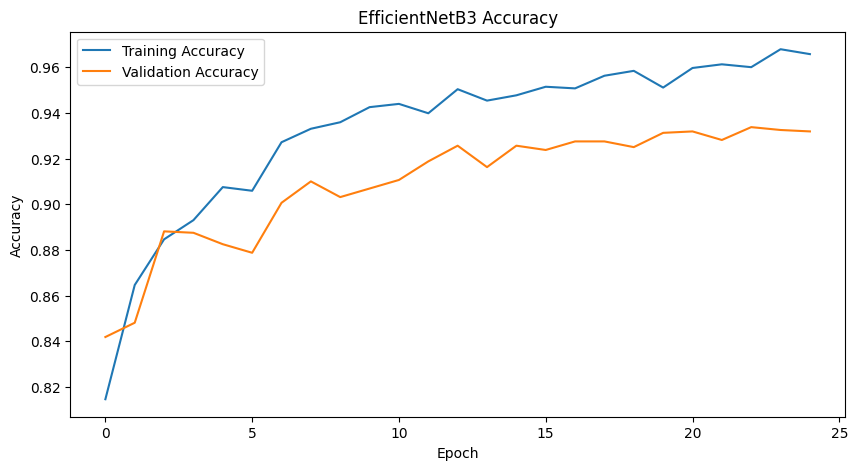

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history1.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history1.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB3 Accuracy")

plt.legend()
plt.show()

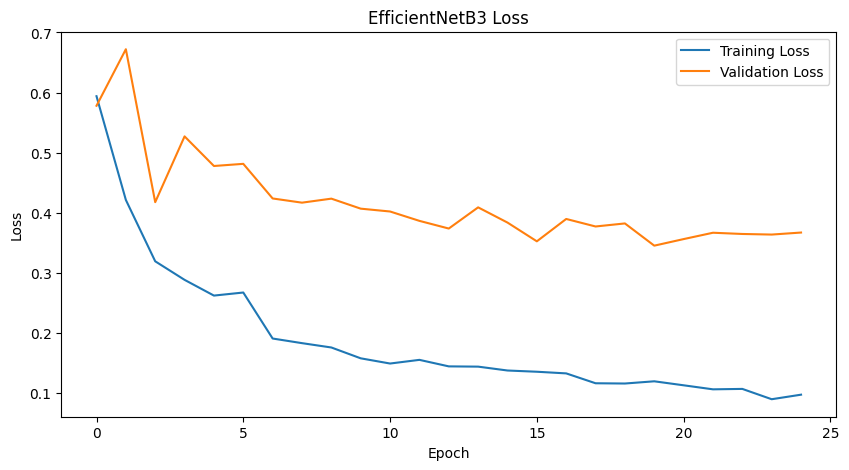

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history1.history["loss"],
    label="Training Loss"
)

plt.plot(
    history1.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB3 Loss")

plt.legend()
plt.show()

In [ ]:
loss, accuracy = model.evaluate(
    test_generator
)

print("Validation/Test Accuracy:", accuracy * 100)

100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 62ms/step - accuracy: 0.9312 - loss: 0.3451
Validation/Test Accuracy: 93.12499761581421


In [ ]:
base_model.trainable = True

# Freeze most of the network
for layer in base_model.layers[:-30]:
    layer.trainable = False

In [ ]:
trainable_count = sum(
    layer.trainable
    for layer in base_model.layers
)

print("Trainable layers:", trainable_count)

Trainable layers: 30


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-6
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history2 = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.8466 - loss: 0.4356
Epoch 1: val_accuracy did not improve from 0.93375
350/350 ━━━━━━━━━━━━━━━━━━━━ 214s 483ms/step - accuracy: 0.8550 - loss: 0.3944 - val_accuracy: 0.8537 - val_loss: 0.4794 - learning_rate: 1.0000e-06
Epoch 2/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.8654 - loss: 0.3565
Epoch 2: val_accuracy did not improve from 0.93375
350/350 ━━━━━━━━━━━━━━━━━━━━ 156s 446ms/step - accuracy: 0.8725 - loss: 0.3388 - val_accuracy: 0.8550 - val_loss: 0.4776 - learning_rate: 1.0000e-06
Epoch 3/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step - accuracy: 0.8715 - loss: 0.3577
Epoch 3: val_accuracy did not improve from 0.93375

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.999999992425728e-07.
350/350 ━━━━━━━━━━━━━━━━━━━━ 156s 445ms/step - accuracy: 0.8768 - loss: 0.3333 - val_accuracy: 0.8537 - val_loss: 0.4772 - learning_rate: 1.0000e-06
Epoch 4/15
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - acc

In [ ]:
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/best_efficientnetB3.keras"
)

In [ ]:
loss, accuracy = best_model.evaluate(
    test_generator
)

print(
    f"Final Accuracy: {accuracy * 100:.2f}%"
)

100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 63ms/step - accuracy: 0.9337 - loss: 0.3645
Final Accuracy: 93.37%


In [ ]:
test_generator.reset()

predictions = best_model.predict(
    test_generator
)

y_pred = np.argmax(
    predictions,
    axis=1
)

y_true = test_generator.classes

100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 68ms/step


In [ ]:
class_names = list(
    test_generator.class_indices.keys()
)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9873    0.7800    0.8715       400
  meningioma     0.8594    0.9625    0.9080       400
     notumor     0.9324    1.0000    0.9650       400
   pituitary     0.9754    0.9925    0.9839       400

    accuracy                         0.9337      1600
   macro avg     0.9386    0.9338    0.9321      1600
weighted avg     0.9386    0.9337    0.9321      1600



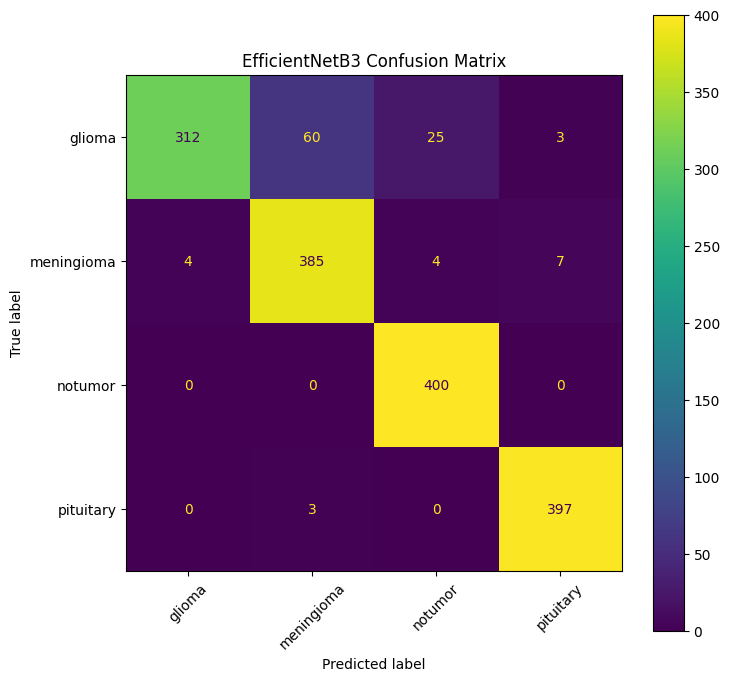

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title(
    "EfficientNetB3 Confusion Matrix"
)

plt.show()

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_tumor(image_path):

    img = load_img(
        image_path,
        target_size=(300, 300)
    )

    img_array = img_to_array(img)

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    predictions = best_model.predict(
        img_array,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)

    class_name = class_names[
        predicted_index
    ]

    confidence = predictions[
        predicted_index
    ] * 100

    print(
        f"Prediction: {class_name}"
    )

    print(
        f"Confidence: {confidence:.2f}%"
    )

    print("\nAll probabilities:")

    for name, probability in zip(
        class_names,
        predictions
    ):
        print(
            f"{name}: {probability * 100:.2f}%"
        )

    return class_name, confidence

In [ ]:
import glob

classes = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

for class_name in classes:

    image_path = glob.glob(
        f"/content/brain_tumor/Testing/{class_name}/*"
    )[0]

    print("\nActual class:", class_name)
    print("Image:", image_path)

    predict_tumor(image_path)


Actual class: glioma
Image: /content/brain_tumor/Testing/glioma/Te-gl_7.jpg
Prediction: glioma
Confidence: 100.00%

All probabilities:
glioma: 100.00%
meningioma: 0.00%
notumor: 0.00%
pituitary: 0.00%

Actual class: meningioma
Image: /content/brain_tumor/Testing/meningioma/Te-me_272.jpg
Prediction: meningioma
Confidence: 99.93%

All probabilities:
glioma: 0.00%
meningioma: 99.93%
notumor: 0.04%
pituitary: 0.03%

Actual class: notumor
Image: /content/brain_tumor/Testing/notumor/Te-no_260.jpg
Prediction: notumor
Confidence: 100.00%

All probabilities:
glioma: 0.00%
meningioma: 0.00%
notumor: 100.00%
pituitary: 0.00%

Actual class: pituitary
Image: /content/brain_tumor/Testing/pituitary/Te-pi_271.jpg
Prediction: pituitary
Confidence: 99.99%

All probabilities:
glioma: 0.00%
meningioma: 0.01%
notumor: 0.00%
pituitary: 99.99%


In [ ]:
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/best_efficientnetB3.keras"
)

test_generator.reset()

predictions = best_model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

100/100 ━━━━━━━━━━━━━━━━━━━━ 3440s 34s/step


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9873    0.7800    0.8715       400
  meningioma     0.8594    0.9625    0.9080       400
     notumor     0.9324    1.0000    0.9650       400
   pituitary     0.9754    0.9925    0.9839       400

    accuracy                         0.9337      1600
   macro avg     0.9386    0.9338    0.9321      1600
weighted avg     0.9386    0.9337    0.9321      1600



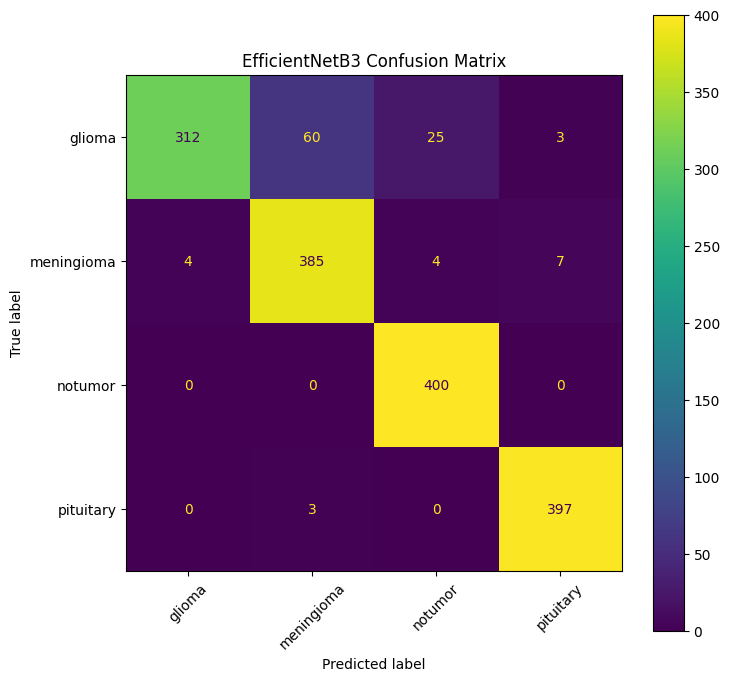

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("EfficientNetB3 Confusion Matrix")
plt.show()

In [ ]:
class_weights = {
    0: 1.30,   # glioma
    1: 1.00,   # meningioma
    2: 1.00,   # notumor
    3: 1.00    # pituitary
}

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rotation_range=12,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.12,
    horizontal_flip=True,
    brightness_range=[0.90, 1.10],
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator()

In [ ]:
import tensorflow as tf
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/best_efficientnetB3.keras"
)

In [ ]:
best_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 10, 10, 1536)   │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,979,325 (45.70 MB)

 Trainable params: 397,572 (1.52 MB)

 Non-trainable params: 10,786,607 (41.15 MB)

 Optimizer params: 795,146 (3.03 MB)

In [ ]:
save_best_only=True

In [ ]:
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/best_efficientnetB3.keras"
)

print("Best model loaded")

Best model loaded


In [ ]:
for i, layer in enumerate(best_model.layers):
    print(i, layer.name, layer.trainable)

0 input_layer_2 True
1 efficientnetb3 False
2 global_average_pooling2d True
3 batch_normalization True
4 dense True
5 dropout True
6 dense_1 True


In [ ]:
base_model = best_model.get_layer("efficientnetb3")

print(base_model.name)
print(len(base_model.layers))

efficientnetb3
385


In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-5]:
    layer.trainable = False

for layer in base_model.layers[-5:]:
    layer.trainable = True

In [ ]:
print("Trainable layers:")

for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

Trainable layers:
block7b_drop
block7b_add
top_conv
top_bn
top_activation


In [ ]:
import tensorflow as tf

best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-7
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
checkpoint_glioma = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop_glioma = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_glioma = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-8,
    verbose=1
)

In [ ]:
import os

TRAIN_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Training"
TEST_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing"

IMG_SIZE = (300, 300)
BATCH_SIZE = 16
SEED = 42

print("Training:", os.path.exists(TRAIN_DIR))
print("Testing :", os.path.exists(TEST_DIR))

Training: True
Testing : True


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rotation_range=12,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.12,
    horizontal_flip=True,
    brightness_range=[0.90, 1.10],
    fill_mode="nearest"
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

Found 5600 images belonging to 4 classes.


In [ ]:
test_datagen = ImageDataGenerator()

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1600 images belonging to 4 classes.


In [ ]:
print("Class indices:", train_generator.class_indices)
print("Training images:", train_generator.samples)
print("Testing images:", test_generator.samples)

Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training images: 5600
Testing images: 1600


In [ ]:
import tensorflow as tf

best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/best_efficientnetB3.keras"
)

print("Best model loaded.")

Best model loaded.


In [ ]:
print(best_model.input_shape)
print(best_model.output_shape)

(None, 300, 300, 3)
(None, 4)


In [ ]:
base_model = best_model.get_layer("efficientnetb3")

print("Base model:", base_model.name)
print("Number of layers:", len(base_model.layers))

Base model: efficientnetb3
Number of layers: 385


In [ ]:
print("Base model:", base_model.name)
print("Number of layers:", len(base_model.layers))

Base model: efficientnetb3
Number of layers: 385


In [ ]:
history_glioma = best_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=8,
    class_weight=class_weights,
    callbacks=[
        checkpoint_glioma,
        early_stop_glioma,
        reduce_lr_glioma
    ]
)

Epoch 1/8
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9707 - loss: 0.0848
Epoch 1: val_accuracy improved from None to 0.93125, saving model to /content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras
350/350 ━━━━━━━━━━━━━━━━━━━━ 2498s 7s/step - accuracy: 0.9636 - loss: 0.0984 - val_accuracy: 0.9312 - val_loss: 0.3818 - learning_rate: 9.0000e-05
Epoch 2/8
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.9737 - loss: 0.0856
Epoch 2: val_accuracy improved from 0.93125 to 0.93250, saving model to /content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras
350/350 ━━━━━━━━━━━━━━━━━━━━ 173s 495ms/step - accuracy: 0.9730 - loss: 0.0851 - val_accuracy: 0.9325 - val_loss: 0.3772 - learning_rate: 9.0000e-05
Epoch 3/8
350/350 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.9655 - loss: 0.0944
Epoch 3

In [ ]:
tuned_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras"
)

test_generator.reset()

loss, accuracy = tuned_model.evaluate(
    test_generator
)

print(f"Accuracy: {accuracy * 100:.2f}%")

100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 72ms/step - accuracy: 0.9381 - loss: 0.3675
Accuracy: 93.81%


In [ ]:
import tensorflow as tf

tuned_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/EfficientNetB3_glioma_tuned.keras"
)

print("✅ Tuned model loaded")

✅ Tuned model loaded


In [ ]:
test_generator.reset()

predictions = tuned_model.predict(
    test_generator,
    verbose=1
)

y_pred = predictions.argmax(axis=1)
y_true = test_generator.classes

class_names = list(
    test_generator.class_indices.keys()
)

print(class_names)

100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 64ms/step
['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

      glioma     0.9815    0.7975    0.8800       400
  meningioma     0.8724    0.9575    0.9130       400
     notumor     0.9324    1.0000    0.9650       400
   pituitary     0.9803    0.9975    0.9888       400

    accuracy                         0.9381      1600
   macro avg     0.9417    0.9381    0.9367      1600
weighted avg     0.9417    0.9381    0.9367      1600



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

[[319  55  24   2]
 [  6 383   5   6]
 [  0   0 400   0]
 [  0   1   0 399]]


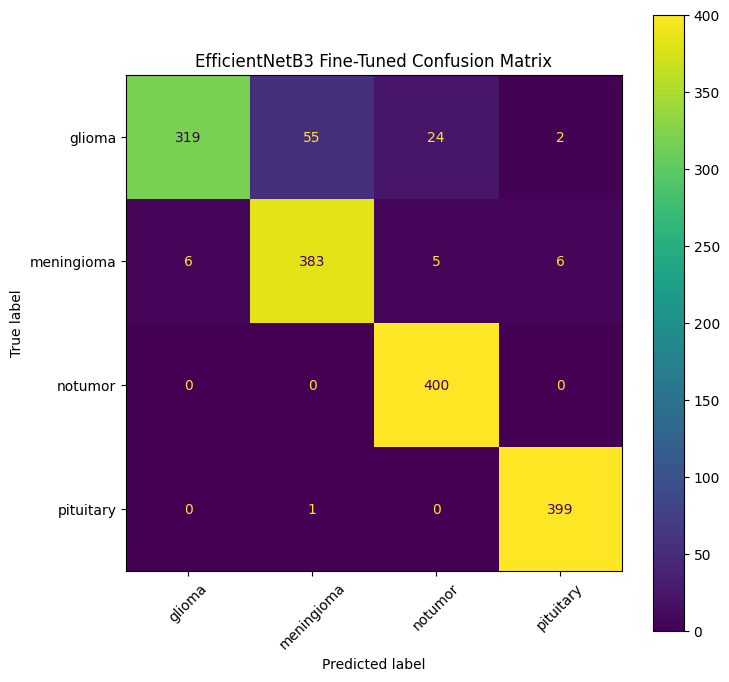

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("EfficientNetB3 Fine-Tuned Confusion Matrix")
plt.show()

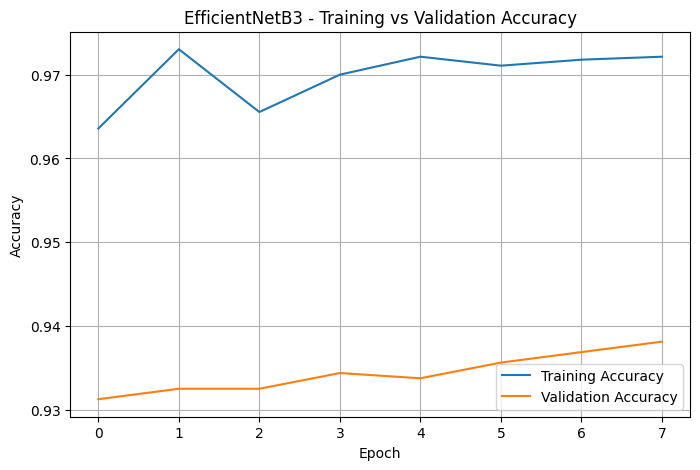

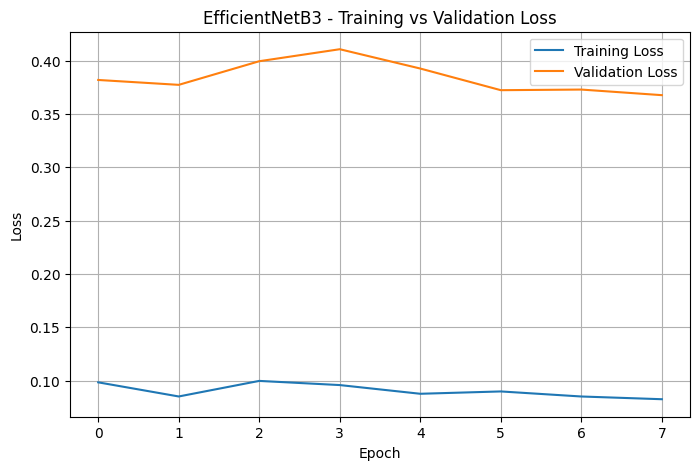

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_glioma.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_glioma.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetB3 - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history_glioma.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_glioma.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetB3 - Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
TRAIN_ORIGINAL_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Training"

TEST_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing"

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.


In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
    class_names=train_ds.class_names
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras import layers, models

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

from sklearn.utils.class_weight import compute_class_weight

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
data_augmentation = tf.keras.Sequential([

    layers.RandomRotation(0.05),

    layers.RandomZoom(0.10),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),

    layers.RandomFlip("horizontal")

], name="data_augmentation")

In [ ]:
base_model = tf.keras.applications.DenseNet201(

    weights="imagenet",

    include_top=False,

    input_shape=(224, 224, 3)

)

print("DenseNet201 loaded successfully!")

DenseNet201 loaded successfully!


In [ ]:
base_model.trainable = False

print("Base model frozen")

Base model frozen


In [ ]:
inputs = layers.Input(
    shape=(224, 224, 3)
)

# Data augmentation
x = data_augmentation(inputs)

# DenseNet preprocessing
x = tf.keras.applications.densenet.preprocess_input(x)

# Feature extraction
x = base_model(
    x,
    training=False
)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

densenet_model = models.Model(
    inputs=inputs,
    outputs=outputs
)

densenet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1920)           │         7,680 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       491,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,822,468 (71.80 MB)

 Trainable params: 496,644 (1.89 MB)

 Non-trainable params: 18,325,824 (69.91 MB)

In [ ]:
densenet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
import tensorflow as tf

checkpoint_path = "/content/drive/MyDrive/DenseNet201_best.keras"

callbacks = [
    # Save the model whenever validation accuracy improves
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    # Reduce learning rate when validation loss stops improving
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configured successfully.")

Callbacks configured successfully.


In [ ]:
import tensorflow as tf

IMG_SIZE = 224
NUM_CLASSES = 4

base_model = tf.keras.applications.DenseNet201(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

print("DenseNet201 loaded successfully.")

DenseNet201 loaded successfully.


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomFlip("horizontal"),

    layers.Lambda(
        tf.keras.applications.densenet.preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(256, activation="relu"),

    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

print("DenseNet201 model created successfully.")

model.summary()

DenseNet201 model created successfully.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1920)           │         7,680 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       491,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,822,468 (71.80 MB)

 Trainable params: 496,644 (1.89 MB)

 Non-trainable params: 18,325,824 (69.91 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
import os
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get class names directly from the directory
class_names = sorted([
    folder for folder in os.listdir(TRAIN_ORIGINAL_DIR)
    if os.path.isdir(os.path.join(TRAIN_ORIGINAL_DIR, folder))
])

print("Class names:", class_names)

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
class_counts = []

for class_name in class_names:
    folder = os.path.join(TRAIN_ORIGINAL_DIR, class_name)

    count = sum(
        1 for file in os.listdir(folder)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    )

    class_counts.append(count)

print("Class counts:", class_counts)

if any(count == 0 for count in class_counts):
    raise ValueError("A class has zero images. Check your dataset folders.")

labels = np.concatenate([
    np.full(count, index)
    for index, count in enumerate(class_counts)
])

classes = np.arange(len(class_names))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=labels
)

class_weights = {
    int(index): float(weight)
    for index, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class counts: [1400, 1400, 1400, 1400]
Class weights: {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0}


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Recreate DenseNet201
base_model = tf.keras.applications.DenseNet201(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Rebuild classification model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomFlip("horizontal"),

    layers.Lambda(
        tf.keras.applications.densenet.preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

print("Model rebuilt successfully.")

Model rebuilt successfully.


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    run_eagerly=True
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
# Check that all model variables have been created
print("Model built:", model.built)
print("Number of model variables:", len(model.variables))
print("Number of trainable variables:", len(model.trainable_variables))

# Check one batch
for images, labels in train_ds.take(1):
    predictions = model(images, training=False)
    print("Input shape:", images.shape)
    print("Output shape:", predictions.shape)

Model built: True
Number of model variables: 1017
Number of trainable variables: 6
Input shape: (16, 224, 224, 3)
Output shape: (16, 4)


In [ ]:
import os
from PIL import Image

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

def scan_images(directory):
    bad_images = []
    total_images = 0

    for root, dirs, files in os.walk(directory):
        for filename in files:
            if not filename.lower().endswith(IMAGE_EXTENSIONS):
                continue

            path = os.path.join(root, filename)
            total_images += 1

            try:
                if os.path.getsize(path) == 0:
                    bad_images.append((path, "Empty file"))
                    continue

                # Verify image integrity
                with Image.open(path) as img:
                    img.verify()

                # Also check that the image can actually be loaded
                with Image.open(path) as img:
                    img.load()

            except Exception as e:
                bad_images.append((path, str(e)))

    print("\nDirectory:", directory)
    print("Total images:", total_images)
    print("Problematic images:", len(bad_images))

    for path, error in bad_images:
        print("\nProblem:", error)
        print("File:", path)

    return bad_images

In [ ]:
bad_train = scan_images(TRAIN_ORIGINAL_DIR)
bad_test = scan_images(TEST_DIR)

print("\nTotal problematic training images:", len(bad_train))
print("Total problematic testing images:", len(bad_test))


Directory: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Training
Total images: 5600
Problematic images: 1

Problem: Empty file
File: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Training/glioma/Tr-gl_1202.jpg

Directory: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing
Total images: 1600
Problematic images: 0

Total problematic training images: 1
Total problematic testing images: 0


In [ ]:
import shutil

QUARANTINE_DIR = "/content/drive/MyDrive/Corrupted_Brain_Tumor_Images"

os.makedirs(QUARANTINE_DIR, exist_ok=True)

all_bad_images = bad_train + bad_test

for index, (path, error) in enumerate(all_bad_images):
    destination = os.path.join(
        QUARANTINE_DIR,
        f"bad_image_{index}_{os.path.basename(path)}"
    )

    shutil.move(path, destination)
    print("Moved:", path)

print("Quarantine completed.")

Moved: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Training/glioma/Tr-gl_1202.jpg
Quarantine completed.


In [ ]:
for images, labels in train_ds.take(1):
    print("Training images:", images.shape)
    print("Training labels:", labels.shape)

for images, labels in valid_ds.take(1):
    print("Validation images:", images.shape)
    print("Validation labels:", labels.shape)

for images, labels in test_ds.take(1):
    print("Testing images:", images.shape)
    print("Testing labels:", labels.shape)

Training images: (16, 224, 224, 3)
Training labels: (16,)
Validation images: (16, 224, 224, 3)
Validation labels: (16,)
Testing images: (16, 224, 224, 3)
Testing labels: (16,)


In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

TRAIN_ORIGINAL_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Training"
TEST_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing"

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

print("Training classes:", train_ds.class_names)
print("Validation classes:", valid_ds.class_names)
print("Testing classes:", test_ds.class_names)

Found 5599 files belonging to 4 classes.
Using 4760 files for training.
Found 5599 files belonging to 4 classes.
Using 839 files for validation.
Found 1600 files belonging to 4 classes.
Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Validation classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
for name, dataset in [
    ("Training", train_ds),
    ("Validation", valid_ds),
    ("Testing", test_ds)
]:
    total = 0

    for images, labels in dataset:
        total += images.shape[0]

    print(name, "images loaded:", total)

Training images loaded: 4760
Validation images loaded: 839
Testing images loaded: 1600


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_names = train_ds.class_names

class_counts = []

for class_name in class_names:
    folder = os.path.join(TRAIN_ORIGINAL_DIR, class_name)

    count = sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    )

    class_counts.append(count)

labels = np.concatenate([
    np.full(count, index)
    for index, count in enumerate(class_counts)
])

classes = np.arange(len(class_names))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=labels
)

class_weights = {
    int(i): float(w)
    for i, w in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 1.0005360972122945, 1: 0.9998214285714285, 2: 0.9998214285714285, 3: 0.9998214285714285}


In [ ]:
import gc
import tensorflow as tf

tf.keras.backend.clear_session()
gc.collect()

print("TensorFlow session cleared.")

TensorFlow session cleared.


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 8
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

print("Training classes:", train_ds.class_names)

Found 5599 files belonging to 4 classes.
Using 4760 files for training.
Found 5599 files belonging to 4 classes.
Using 839 files for validation.
Found 1600 files belonging to 4 classes.
Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Recreate DenseNet201
base_model = tf.keras.applications.DenseNet201(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Rebuild classification model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomFlip("horizontal"),

    layers.Lambda(
        tf.keras.applications.densenet.preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

print("Model rebuilt successfully.")

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Model rebuilt successfully.


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1920)           │         7,680 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       491,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,822,468 (71.80 MB)

 Trainable params: 496,644 (1.89 MB)

 Non-trainable params: 18,325,824 (69.91 MB)

In [ ]:
history1 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
595/595 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.6509 - loss: 0.8978
Epoch 1: val_accuracy improved from None to 0.87247, saving model to /content/drive/MyDrive/DenseNet201_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DenseNet201_best.keras
595/595 ━━━━━━━━━━━━━━━━━━━━ 101s 127ms/step - accuracy: 0.7546 - loss: 0.6683 - val_accuracy: 0.8725 - val_loss: 0.3786 - learning_rate: 1.0000e-04
Epoch 2/30
595/595 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.8357 - loss: 0.4523
Epoch 2: val_accuracy improved from 0.87247 to 0.88677, saving model to /content/drive/MyDrive/DenseNet201_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DenseNet201_best.keras
595/595 ━━━━━━━━━━━━━━━━━━━━ 68s 114ms/step - accuracy: 0.8416 - loss: 0.4335 - val_accuracy: 0.8868 - val_loss: 0.3405 - learning_rate: 1.0000e-04
Epoch 3/30
595/595 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8691 - loss: 0.3683
Epoch 3: val_accuracy improved from 0.88677 to 

In [ ]:
# Unfreeze the DenseNet201 base model
base_model.trainable = True

# Freeze all layers first
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze last 50 layers except BatchNormalization
for layer in base_model.layers[-50:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

print("Trainable layers:",
      sum(1 for layer in base_model.layers if layer.trainable))

Trainable layers: 36


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully.")

Fine-tuning model compiled successfully.


In [ ]:
EPOCHS_PHASE2 = 30

history2 = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS_PHASE2,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
595/595 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.9621 - loss: 0.1040
Epoch 1: val_accuracy did not improve from 0.94160
595/595 ━━━━━━━━━━━━━━━━━━━━ 99s 127ms/step - accuracy: 0.9634 - loss: 0.1079 - val_accuracy: 0.9344 - val_loss: 0.1931 - learning_rate: 1.0000e-05
Epoch 2/30
595/595 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9601 - loss: 0.1024
Epoch 2: val_accuracy did not improve from 0.94160
595/595 ━━━━━━━━━━━━━━━━━━━━ 67s 112ms/step - accuracy: 0.9662 - loss: 0.0956 - val_accuracy: 0.9416 - val_loss: 0.1809 - learning_rate: 1.0000e-05
Epoch 3/30
595/595 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9617 - loss: 0.1021
Epoch 3: val_accuracy improved from 0.94160 to 0.94279, saving model to /content/drive/MyDrive/DenseNet201_best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/DenseNet201_best.keras
595/595 ━━━━━━━━━━━━━━━━━━━━ 69s 115ms/step - accuracy: 0.9651 - loss: 0.0977 - val_accuracy: 0.9428 - val_loss: 0.1763 - learning_rate: 1.000

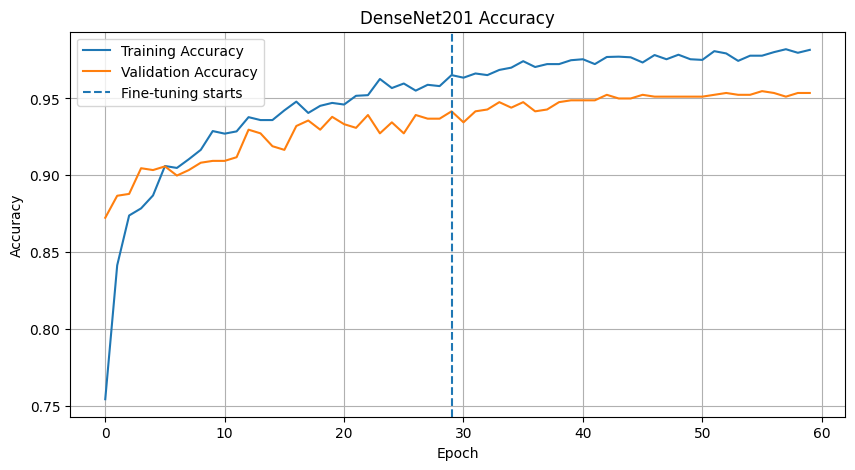

In [ ]:
import matplotlib.pyplot as plt

train_acc = (
    history1.history["accuracy"] +
    history2.history["accuracy"]
)

val_acc = (
    history1.history["val_accuracy"] +
    history2.history["val_accuracy"]
)

plt.figure(figsize=(10, 5))

plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")

plt.axvline(
    x=len(history1.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title("DenseNet201 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

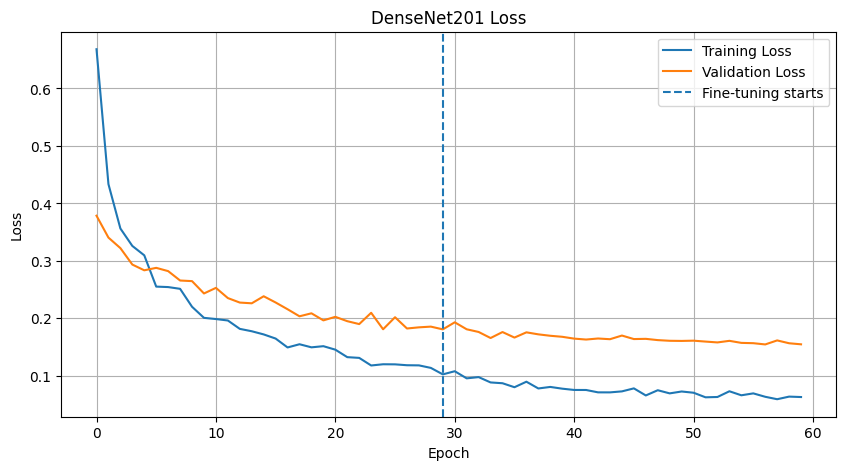

In [ ]:
train_loss = (
    history1.history["loss"] +
    history2.history["loss"]
)

val_loss = (
    history1.history["val_loss"] +
    history2.history["val_loss"]
)

plt.figure(figsize=(10, 5))

plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.axvline(
    x=len(history1.history["loss"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title("DenseNet201 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input

In [ ]:
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/DenseNet201_best.keras",
    custom_objects={
        "preprocess_input": preprocess_input
    }
)

print("Best DenseNet201 model loaded successfully!")

Best DenseNet201 model loaded successfully!


In [ ]:
import tensorflow as tf

TEST_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing"

IMG_SIZE = 224
BATCH_SIZE = 4

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int"
)

print("Test dataset created successfully!")
print("Classes:", test_ds.class_names)

Found 1600 files belonging to 4 classes.
Test dataset created successfully!
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

400/400 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.9237 - loss: 0.3631
Test Accuracy: 92.37%
Test Loss: 0.3631


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predicted labels
y_prob = best_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Get actual class order
class_names = test_ds.class_names

# Classification report
print("CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("CONFUSION MATRIX")
print(cm)

400/400 ━━━━━━━━━━━━━━━━━━━━ 27s 52ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9903    0.7675    0.8648       400
  meningioma     0.8427    0.9375    0.8876       400
     notumor     0.9365    0.9950    0.9648       400
   pituitary     0.9476    0.9950    0.9707       400

    accuracy                         0.9237      1600
   macro avg     0.9293    0.9238    0.9220      1600
weighted avg     0.9293    0.9237    0.9220      1600

CONFUSION MATRIX
[[307  67  24   2]
 [  3 375   3  19]
 [  0   1 398   1]
 [  0   2   0 398]]


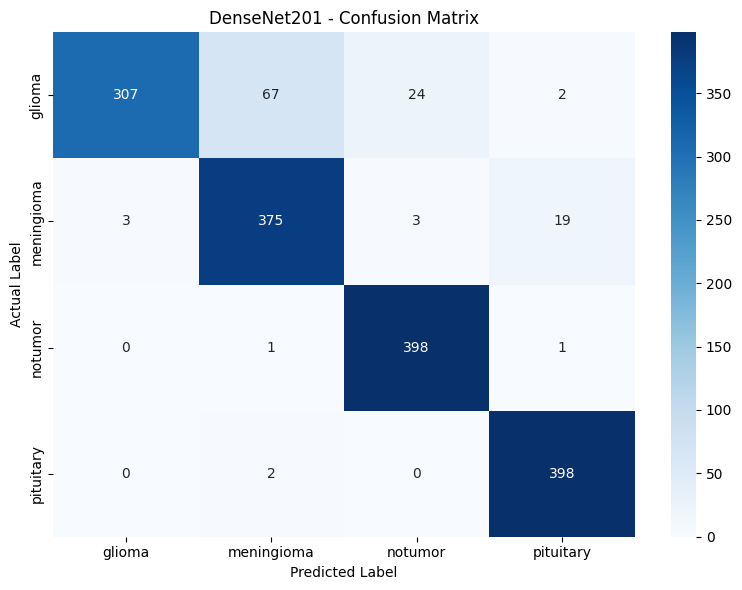

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DenseNet201 - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Get class names and image paths
class_names = test_ds.class_names
file_paths = test_ds.file_paths

# 2. Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# 3. Get predicted labels
y_prob = best_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# 4. Find glioma index
glioma_index = class_names.index("glioma")

# 5. Find incorrectly classified glioma images
wrong_glioma = np.where(
    (y_true == glioma_index) &
    (y_pred != y_true)
)[0]

print("Total test images:", len(y_true))
print("Misclassified glioma images:", len(wrong_glioma))

# 6. Display first 20 incorrect predictions
for i in wrong_glioma[:20]:
    print(
        "Image:", file_paths[i],
        "| Actual: glioma",
        "| Predicted:", class_names[y_pred[i]]
    )

400/400 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step
Total test images: 1600
Misclassified glioma images: 93
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_1.jpg | Actual: glioma | Predicted: notumor
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_102.jpg | Actual: glioma | Predicted: notumor
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_104.jpg | Actual: glioma | Predicted: meningioma
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_106.jpg | Actual: glioma | Predicted: meningioma
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_109.jpg | Actual: glioma | Predicted: meningioma
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_110.jpg | Actual: glioma | Predicted: meningioma
Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_115.jpg | Actual: glioma | Predicted: meningioma
Image: /conte

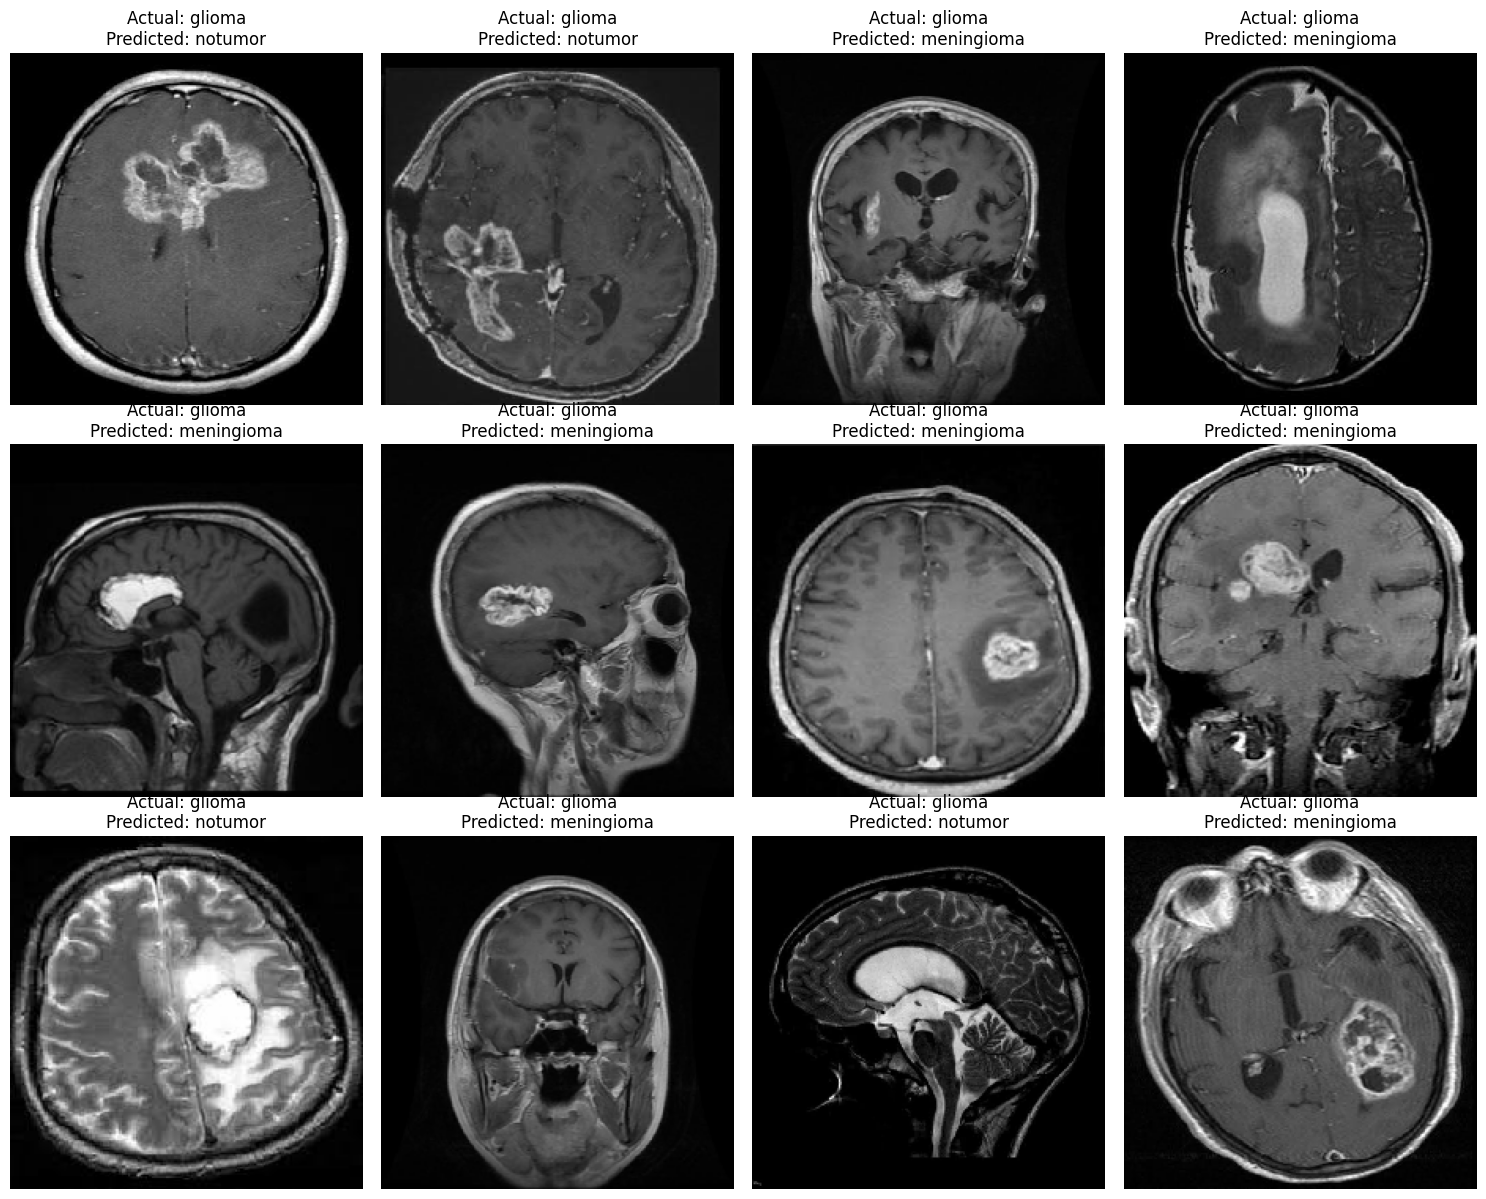

In [ ]:
plt.figure(figsize=(15, 12))

for j, idx in enumerate(wrong_glioma[:12]):
    image = tf.keras.utils.load_img(
        file_paths[idx],
        target_size=(224, 224)
    )

    plt.subplot(3, 4, j + 1)
    plt.imshow(image)
    plt.title(f"Actual: glioma\nPredicted: {class_names[y_pred[idx]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for idx in wrong_glioma[:15]:

    probabilities = y_prob[idx]

    print("\nImage:", file_paths[idx])
    print("Actual: glioma")

    for name, probability in zip(class_names, probabilities):
        print(f"{name}: {probability * 100:.2f}%")


Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_1.jpg
Actual: glioma
glioma: 27.13%
meningioma: 26.95%
notumor: 45.34%
pituitary: 0.59%

Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_102.jpg
Actual: glioma
glioma: 37.23%
meningioma: 10.00%
notumor: 51.21%
pituitary: 1.57%

Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_104.jpg
Actual: glioma
glioma: 26.55%
meningioma: 73.35%
notumor: 0.00%
pituitary: 0.09%

Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_106.jpg
Actual: glioma
glioma: 0.20%
meningioma: 99.29%
notumor: 0.52%
pituitary: 0.00%

Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_109.jpg
Actual: glioma
glioma: 1.04%
meningioma: 75.11%
notumor: 11.56%
pituitary: 12.28%

Image: /content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing/glioma/Te-gl_110.jpg
Actual: glioma
glioma: 36.54%
meningioma: 63.44%
notumor: 0.00%
pit

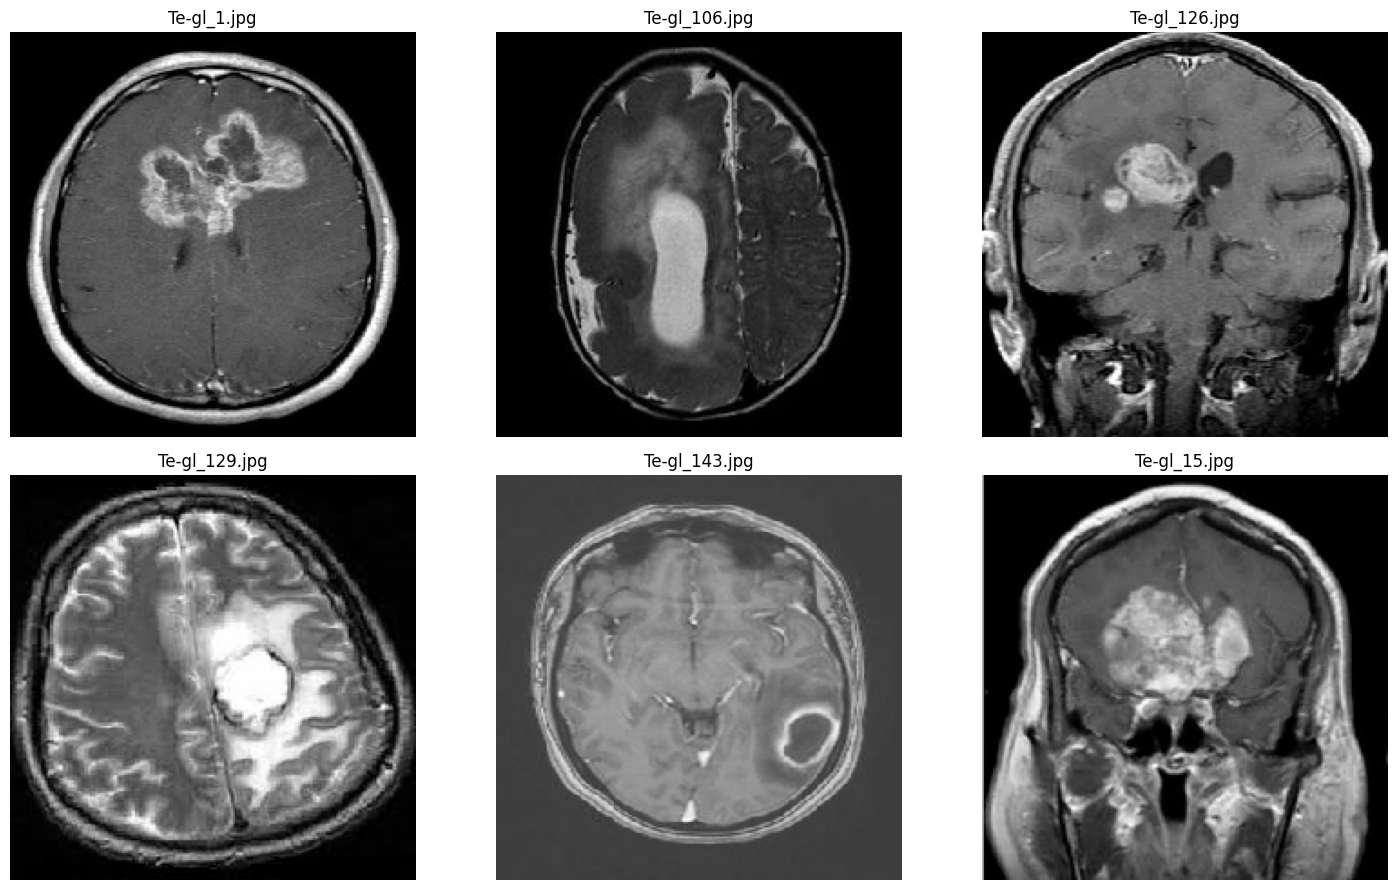

In [ ]:
import matplotlib.pyplot as plt
import os
import tensorflow as tf

selected_images = [
    "Te-gl_1.jpg",
    "Te-gl_106.jpg",
    "Te-gl_126.jpg",
    "Te-gl_129.jpg",
    "Te-gl_143.jpg",
    "Te-gl_15.jpg"
]

plt.figure(figsize=(15, 9))

for i, filename in enumerate(selected_images):

    path = os.path.join(
        TEST_DIR,
        "glioma",
        filename
    )

    img = tf.keras.utils.load_img(
        path,
        target_size=(224, 224)
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

TRAIN_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Training"

for class_name in sorted(os.listdir(TRAIN_DIR)):
    class_path = os.path.join(TRAIN_DIR, class_name)

    if os.path.isdir(class_path):
        count = sum(
            1 for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )
        print(f"{class_name}: {count} images")

glioma: 1399 images
meningioma: 1400 images
notumor: 1400 images
pituitary: 1400 images


In [ ]:
import tensorflow as tf
import os

TRAIN_ORIGINAL_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Training"

IMG_SIZE = 224
BATCH_SIZE = 4
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

print("Training and validation datasets created!")
print("Classes:", train_ds.class_names)

Found 5599 files belonging to 4 classes.
Using 4760 files for training.
Found 5599 files belonging to 4 classes.
Using 839 files for validation.
Training and validation datasets created!
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = np.concatenate([
    labels.numpy() for images, labels in train_ds
])

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("\nClass weights:")

for i, weight in class_weights.items():
    print(f"{train_ds.class_names[i]}: {weight:.4f}")


Class weights:
glioma: 0.9867
meningioma: 0.9958
notumor: 1.0145
pituitary: 1.0034


In [ ]:
experimental_class_weights = {
    0: 1.15,  # glioma
    1: 1.00,  # meningioma
    2: 1.00,  # notumor
    3: 1.00   # pituitary
}

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input

best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/DenseNet201_best.keras",
    custom_objects={
        "preprocess_input": preprocess_input
    }
)

print("Original best DenseNet201 loaded!")

Original best DenseNet201 loaded!


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.layers import Lambda

In [ ]:
experimental_model = tf.keras.models.clone_model(
    best_model,
    clone_function=lambda layer: (
        Lambda(preprocess_input, name=layer.name)
        if isinstance(layer, Lambda)
        else layer.__class__.from_config(layer.get_config())
    )
)

experimental_model.set_weights(best_model.get_weights())

print("Experimental model created successfully!")

Experimental model created successfully!


In [ ]:
experimental_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 7, 7, 1920)     │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1920)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1920)           │         7,680 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       491,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,543,118 (89.81 MB)

 Trainable params: 2,360,324 (9.00 MB)

 Non-trainable params: 16,462,144 (62.80 MB)

 Optimizer params: 4,720,650 (18.01 MB)

In [ ]:
for i, layer in enumerate(experimental_model.layers):
    print(i, layer.name, type(layer).__name__)

0 random_rotation RandomRotation
1 random_zoom RandomZoom
2 random_translation RandomTranslation
3 random_flip RandomFlip
4 lambda Lambda
5 densenet201 Functional
6 global_average_pooling2d GlobalAveragePooling2D
7 batch_normalization BatchNormalization
8 dense Dense
9 dropout Dropout
10 dense_1 Dense


In [ ]:
base_model = next(
    layer for layer in experimental_model.layers
    if isinstance(layer, tf.keras.Model)
    and "densenet" in layer.name.lower()
)

print("Backbone found:", base_model.name)

Backbone found: densenet201


In [ ]:
base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-50:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

print("Last 50 DenseNet201 layers configured for fine-tuning.")

Last 50 DenseNet201 layers configured for fine-tuning.


In [ ]:
print("Total DenseNet layers:", len(base_model.layers))

print(
    "Trainable DenseNet layers:",
    sum(1 for layer in base_model.layers if layer.trainable)
)

Total DenseNet layers: 707
Trainable DenseNet layers: 36


In [ ]:
experimental_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
experimental_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Experimental model compiled successfully.")

Experimental model compiled successfully.


In [ ]:
experimental_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/MyDrive/DenseNet201_experimental_best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

history_experimental = experimental_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=[experimental_checkpoint, early_stop],
    class_weight={0: 1.15, 1: 1.0, 2: 1.0, 3: 1.0}
)

Epoch 1/30
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9392 - loss: 0.1700
Epoch 1: val_accuracy improved from None to 0.95232, saving model to /content/drive/MyDrive/DenseNet201_experimental_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DenseNet201_experimental_best.keras
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 261s 198ms/step - accuracy: 0.9393 - loss: 0.1657 - val_accuracy: 0.9523 - val_loss: 0.1648
Epoch 2/30
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9438 - loss: 0.1561
Epoch 2: val_accuracy did not improve from 0.95232
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 88s 74ms/step - accuracy: 0.9443 - loss: 0.1559 - val_accuracy: 0.9487 - val_loss: 0.1649
Epoch 3/30
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9496 - loss: 0.1529
Epoch 3: val_accuracy did not improve from 0.95232
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 86s 72ms/step - accuracy: 0.9424 - loss: 0.1606 - val_accuracy: 0.9464 - val_loss: 0.1689
Epoch 4/30
1190/1190 ━━━━━━━━━━━━━━━━━━━━ 0s

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input

experimental_best = tf.keras.models.load_model(
    "/content/drive/MyDrive/DenseNet201_experimental_best.keras",
    custom_objects={"preprocess_input": preprocess_input}
)

print("Experimental best model loaded successfully.")

Experimental best model loaded successfully.


In [ ]:
import tensorflow as tf

TEST_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Testing"

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(224, 224),
    batch_size=4,
    shuffle=False,
    label_mode="int"
)

print("Classes:", test_ds.class_names)
print("Test dataset created successfully!")

Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Test dataset created successfully!


In [ ]:
test_loss, test_accuracy = experimental_best.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

400/400 ━━━━━━━━━━━━━━━━━━━━ 458s 1s/step - accuracy: 0.9337 - loss: 0.3620
Test Accuracy: 93.37%
Test Loss: 0.3620


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = experimental_best.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.class_names,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

400/400 ━━━━━━━━━━━━━━━━━━━━ 429s 1s/step
              precision    recall  f1-score   support

      glioma     0.9937    0.7875    0.8787       400
  meningioma     0.8565    0.9550    0.9031       400
     notumor     0.9433    0.9975    0.9696       400
   pituitary     0.9614    0.9950    0.9779       400

    accuracy                         0.9337      1600
   macro avg     0.9387    0.9338    0.9323      1600
weighted avg     0.9387    0.9337    0.9323      1600

Confusion Matrix:
[[315  61  22   2]
 [  2 382   2  14]
 [  0   1 399   0]
 [  0   2   0 398]]


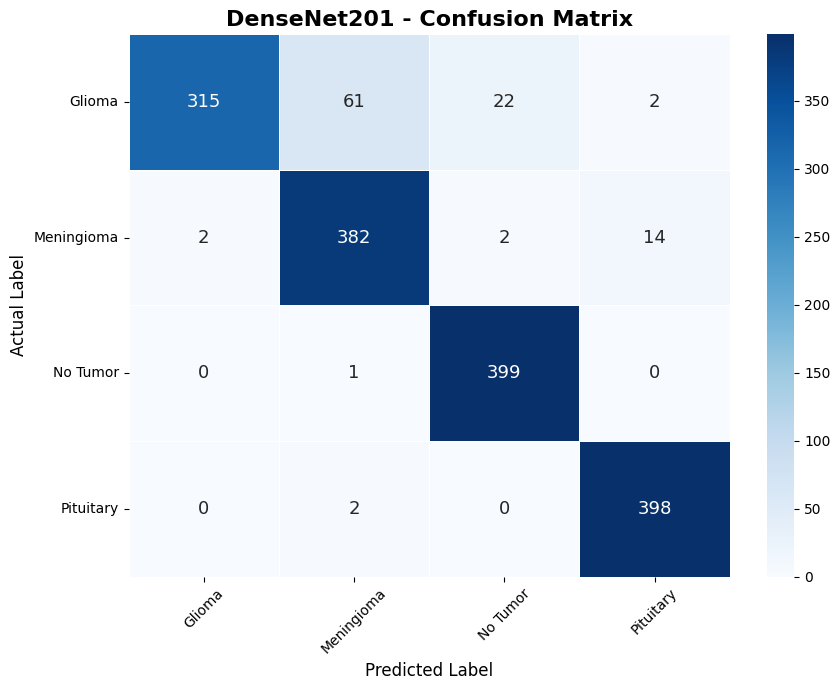

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Class names
class_names = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

# Plot
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    linecolor='white',
    cbar=True,
    annot_kws={"size": 13}
)

plt.title('DenseNet201 - Confusion Matrix', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

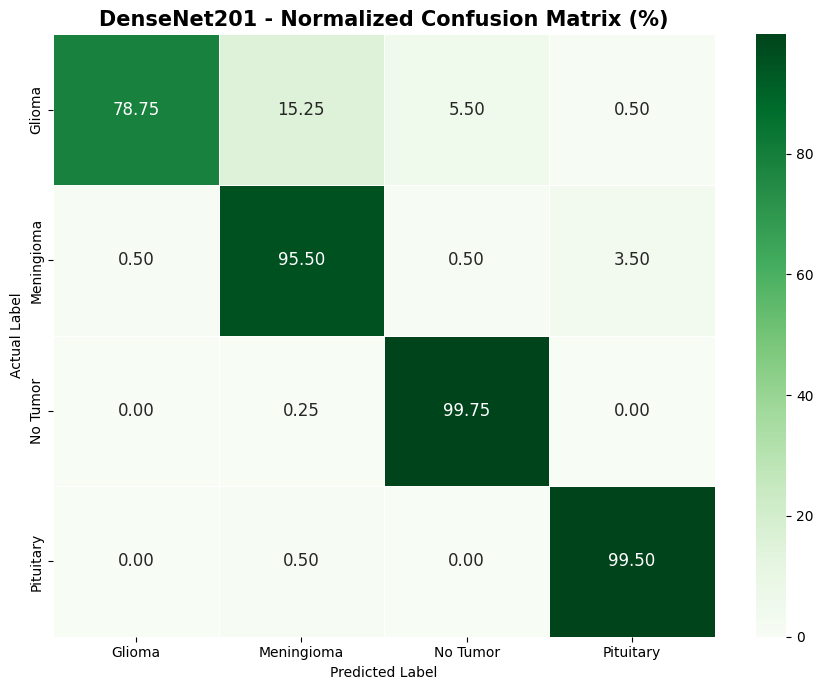

In [ ]:
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt='.2f',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    linecolor='white',
    cbar=True,
    annot_kws={"size": 12}
)

plt.title('DenseNet201 - Normalized Confusion Matrix (%)',
          fontsize=15, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()
plt.show()

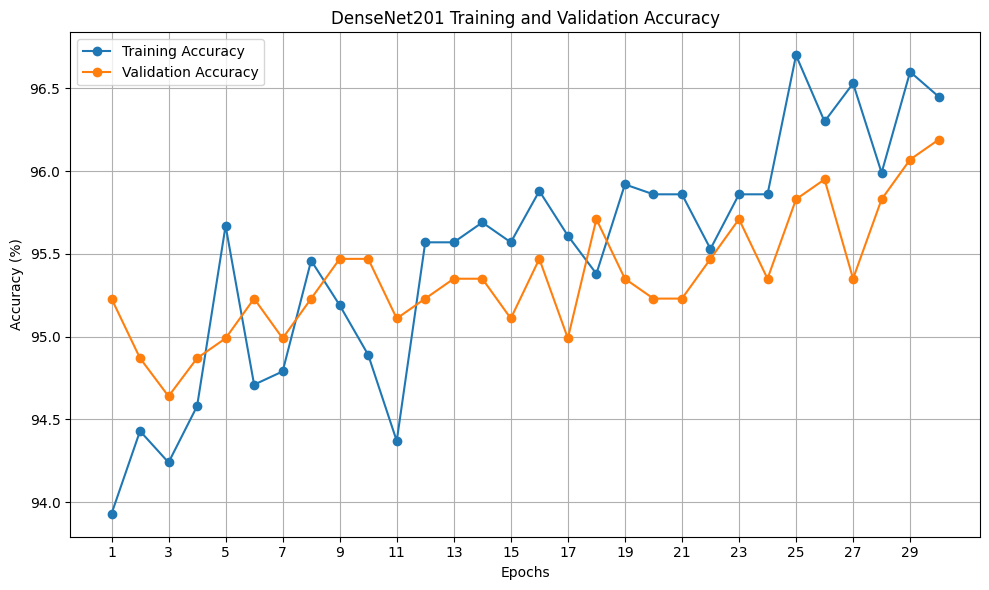

In [ ]:
import matplotlib.pyplot as plt

epochs = list(range(1, 31))

train_accuracy = [
    93.93, 94.43, 94.24, 94.58, 95.67,
    94.71, 94.79, 95.46, 95.19, 94.89,
    94.37, 95.57, 95.57, 95.69, 95.57,
    95.88, 95.61, 95.38, 95.92, 95.86,
    95.86, 95.53, 95.86, 95.86, 96.70,
    96.30, 96.53, 95.99, 96.60, 96.45
]

val_accuracy = [
    95.23, 94.87, 94.64, 94.87, 94.99,
    95.23, 94.99, 95.23, 95.47, 95.47,
    95.11, 95.23, 95.35, 95.35, 95.11,
    95.47, 94.99, 95.71, 95.35, 95.23,
    95.23, 95.47, 95.71, 95.35, 95.83,
    95.95, 95.35, 95.83, 96.07, 96.19
]

plt.figure(figsize=(10, 6))

plt.plot(epochs, train_accuracy, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracy, marker='o', label='Validation Accuracy')

plt.title('DenseNet201 Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.xticks(range(1, 31, 2))
plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf

TRAIN_ORIGINAL_DIR = "/content/drive/MyDrive/Colab Notebooks/brain_tumor/Training"

valid_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_ORIGINAL_DIR,
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=4,
    label_mode="int"
)

print(valid_ds.class_names)

Found 5599 files belonging to 4 classes.
Using 839 files for validation.
['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
from tensorflow.keras.applications.densenet import preprocess_input

experimental_best = tf.keras.models.load_model(
    "/content/drive/MyDrive/DenseNet201_experimental_best.keras",
    custom_objects={"preprocess_input": preprocess_input}
)

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Actual labels
val_true = np.concatenate([
    labels.numpy() for images, labels in valid_ds
])

# Predictions
val_prob = experimental_best.predict(valid_ds)
val_pred = np.argmax(val_prob, axis=1)

# Classification report
print("VALIDATION CLASSIFICATION REPORT")

print(classification_report(
    val_true,
    val_pred,
    target_names=valid_ds.class_names,
    digits=4
))

# Confusion matrix
print("VALIDATION CONFUSION MATRIX")

print(confusion_matrix(val_true, val_pred))

210/210 ━━━━━━━━━━━━━━━━━━━━ 237s 1s/step
VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.2304    0.2280    0.2292       193
  meningioma     0.2589    0.2488    0.2537       205
     notumor     0.2613    0.2555    0.2584       227
   pituitary     0.2576    0.2757    0.2664       214

    accuracy                         0.2527       839
   macro avg     0.2520    0.2520    0.2519       839
weighted avg     0.2527    0.2527    0.2526       839

VALIDATION CONFUSION MATRIX
[[44 37 54 58]
 [48 51 58 48]
 [48 57 58 64]
 [51 52 52 59]]


Brain Tumor Detection System Started!

UPLOAD A BRAIN MRI IMAGE


Saving Te-pi_9.jpg to Te-pi_9.jpg


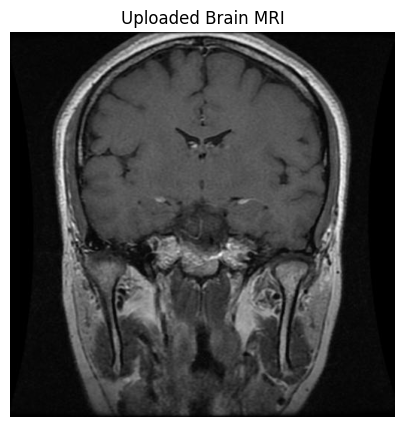


       BRAIN TUMOR CLASSIFICATION

Predicted Class : PITUITARY
Confidence      : 100.00%

Class Probabilities:
Glioma         : 0.00%
Meningioma     : 0.00%
Notumor        : 0.00%
Pituitary      : 100.00%

Do you want to predict another image? (yes/no): no

Brain Tumor Detection System Closed.


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Class names (must match training order)
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

print("Brain Tumor Detection System Started!")

while True:

    print("\n" + "=" * 50)
    print("UPLOAD A BRAIN MRI IMAGE")
    print("=" * 50)

    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        continue

    for filename in uploaded.keys():

        try:
            # Load image
            img = Image.open(filename).convert("RGB")

            # Resize image
            img_resized = img.resize((224, 224))

            # Convert to array
            img_array = np.array(img_resized, dtype=np.float32)

            # Add batch dimension
            img_array = np.expand_dims(img_array, axis=0)

            # Prediction
            predictions = model.predict(img_array, verbose=0)[0]

            predicted_index = np.argmax(predictions)
            predicted_class = class_names[predicted_index]
            confidence = predictions[predicted_index] * 100

            # Display image
            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.axis("off")
            plt.title("Uploaded Brain MRI")
            plt.show()

            # Display prediction
            print("\n" + "=" * 50)
            print("       BRAIN TUMOR CLASSIFICATION")
            print("=" * 50)

            print(f"\nPredicted Class : {predicted_class.upper()}")
            print(f"Confidence      : {confidence:.2f}%")

            print("\nClass Probabilities:")

            for name, probability in zip(class_names, predictions):
                print(f"{name.capitalize():15}: {probability * 100:.2f}%")

            print("=" * 50)

        except Exception as e:
            print(f"Error processing {filename}: {e}")

    # Ask whether to continue
    choice = input("\nDo you want to predict another image? (yes/no): ")

    if choice.strip().lower() not in ["yes", "y"]:
        print("\nBrain Tumor Detection System Closed.")
        break